In [2]:
from coviar import load

In [38]:
video = '/notebooks/BaseballPitchingtarget_BaseballPitchingCage_throw_u_cm_np1_ba_med_1.mp4'
i1 = load(video, 0, 0, 0, True)
i2 = load(video, 5, 0, 0, True)
i3 = load(video, 7, 0, 0, True)


r1 = load(video,5, 1, 2, True)
r2 = load(video,5, 3, 2, True)
r3 = load(video,5, 9, 2, True)

m1 = load(video, 5, 8, 1, True)
m2 = load(video, 6, 4, 1, True)
m3 = load(video, 6, 8, 1, True)

In [3]:
print(mv.dtype)
print(mv.max())
print(mv.min())
print(res.dtype)
print(res.max())
print(res.min())
print(i.dtype)
print(i.max())
print(i.min())

int32
255
-253


In [34]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import hsv_to_rgb


def _as_list(x):
    """Accept one frame (H, W, C), a list/tuple of frames, or a stacked array (N, H, W, C)."""
    if isinstance(x, (list, tuple)):
        return [np.asarray(f) for f in x]
    x = np.asarray(x)
    return list(x) if x.ndim == 4 else [x]


def _make_axes(n, titles, default_title, figsize_per=(4, 3.2)):
    fig, axes = plt.subplots(
        1, n, figsize=(figsize_per[0] * n, figsize_per[1]),
        squeeze=False, constrained_layout=True,
    )
    axes = axes[0]
    if titles is None:
        titles = [f"{default_title} {k}" for k in range(n)] if n > 1 else [default_title]
    for ax, t in zip(axes, titles):
        ax.set_title(t)
        ax.axis("off")
    return fig, axes


def show_iframes(iframes, bgr=False, titles=None):
    """iframes: one (H, W, 3) frame or a list of them, shown in a row. Set bgr=True for OpenCV frames."""
    frames = _as_list(iframes)
    fig, axes = _make_axes(len(frames), titles, "I-frame")

    for ax, f in zip(axes, frames):
        if bgr:
            f = f[..., ::-1]
        if f.dtype != np.uint8:
            f = np.clip(f * (255 if f.max() <= 1.0 else 1), 0, 255).astype(np.uint8)
        ax.imshow(f)
    plt.show()


def show_residuals(residuals, mode="shifted", bgr=False, titles=None):
    """
    residuals: one (H, W, 3) signed residual or a list of them, shown in a row.
    mode:
      "shifted" -> res + 128 (gray = zero residual)
      "abs"     -> |res| with a shared robust normalization (black = zero residual)
    """
    frames = [f.astype(np.float32) for f in _as_list(residuals)]
    if bgr:
        frames = [f[..., ::-1] for f in frames]
    if mode not in ("shifted", "abs"):
        raise ValueError("mode must be 'shifted' or 'abs'")

    if mode == "abs":
        scale = np.percentile(np.concatenate([np.abs(f).ravel() for f in frames]), 99) + 1e-8

    fig, axes = _make_axes(len(frames), titles, f"Residual ({mode})")
    for ax, f in zip(axes, frames):
        if mode == "shifted":
            vis = np.clip(f + 128, 0, 255)
        else:
            vis = np.clip(np.abs(f) / scale * 255, 0, 255)
        ax.imshow(vis.astype(np.uint8))
    plt.show()


def show_motion_vectors(mvs, mode="magnitude", cmap="jet", titles=None):
    """
    mvs: one (H, W, 2) array with channels (dx, dy), or a list of them, shown in a row.
    mode:
      "magnitude" -> heatmap of ||(dx, dy)|| with one shared scale + colorbar
      "flow"      -> HSV: hue = direction, value = magnitude (shared scale)
    """
    frames = [f.astype(np.float32) for f in _as_list(mvs)]
    mags = [np.sqrt(f[..., 0] ** 2 + f[..., 1] ** 2) for f in frames]
    if mode not in ("magnitude", "flow"):
        raise ValueError("mode must be 'magnitude' or 'flow'")

    fig, axes = _make_axes(len(frames), titles, f"MV ({mode})")

    if mode == "magnitude":
        vmax = max(m.max() for m in mags) + 1e-8
        for ax, m in zip(axes, mags):
            im = ax.imshow(m, cmap=cmap, vmin=0, vmax=vmax)
        fig.colorbar(im, ax=list(axes), fraction=0.03, pad=0.02, label="magnitude (px)")
    else:
        scale = np.percentile(np.concatenate([m.ravel() for m in mags]), 99) + 1e-8
        for ax, f, m in zip(axes, frames, mags):
            ang = (np.arctan2(f[..., 1], f[..., 0]) + np.pi) / (2 * np.pi)
            hsv = np.stack([ang, np.ones_like(ang), np.clip(m / scale, 0, 1)], axis=-1)
            ax.imshow(hsv_to_rgb(hsv))
    plt.show()


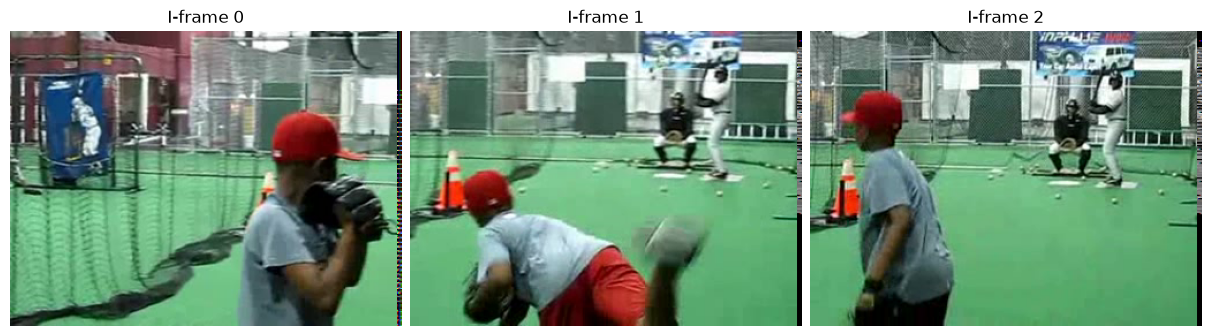

In [42]:
show_iframes([i1, i2, i3], bgr=True)

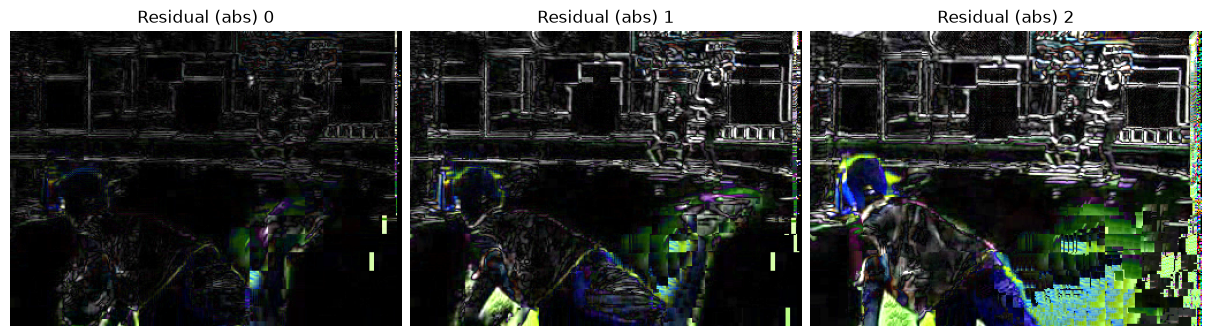

In [40]:
show_residuals([r1, r2, r3], mode="abs")

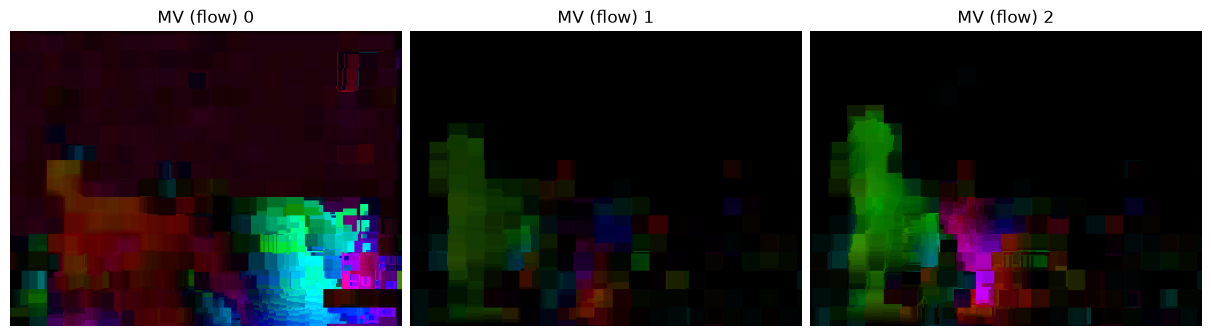

In [41]:
show_motion_vectors([m1, m2, m3], mode="flow")